# 02: Starlink 34343: what first/last-GP queries return
The satellite (NORAD 64157, launch 2025-112) fragmented around 29 March 2026. Two debris pieces were ever catalogued, and both reentered. Without Space-Track history, CelesTrak's `gp-first.php` and `gp-last.php` are the only way to see them.

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": .3})
ROOT = Path.cwd().parent
W = ROOT / "warehouse_repo" / "warehouse"
B = ROOT / "build_out"
from kessler.warehouse.db import connect
con = connect(W)

In [2]:
q = con.sql("SELECT norad_cat_id, object_name, epoch, mean_motion, eccentricity, bstar, source_query, is_first_gp, is_last_gp FROM gp_elements WHERE object_id LIKE '2025-112%' AND (object_name LIKE '%34343%') ORDER BY norad_cat_id, epoch").df(); q

,norad_cat_id,object_name,epoch,mean_motion,eccentricity,bstar,source_query,is_first_gp,is_last_gp
0,64157,STARLINK-34343,2025-06-02 16:00:01.999872-04:00,15.938658,0.000110,-0.004497,first:INTDES=2025-112,True,False
1,64157,STARLINK-34343,2026-10-19 05:43:21.502272-04:00,15.090123,0.001478,0.001068,current:INTDES=2025-112,False,True
2,69729,STARLINK-34343 DEB,2026-06-25 12:12:14.085792-04:00,15.865593,0.002637,0.037037,first:INTDES=2025-112,True,True
3,69730,STARLINK-34343 DEB,2026-06-29 11:45:20.414592-04:00,15.183186,0.002306,0.007249,first:INTDES=2025-112,True,False
4,69730,STARLINK-34343 DEB,2026-09-05 17:20:26.409120-04:00,15.888320,0.001765,0.013804,last:INTDES=2025-112,False,True


**Observation.** The debris first-GP epochs are 25 and 29 June 2026, about **90 days after** the reported event. Back-propagating decaying fragments that far with SGP4 is unreliable, which is why the solver flags `LONG_BACKPROP` and `LOW_CONFIDENCE`.

In [3]:
con.sql("SELECT norad_cat_id, object_name, object_type, decay_date FROM satcat_latest WHERE object_name LIKE 'STARLINK-34343%'").df()

,norad_cat_id,object_name,object_type,decay_date
0,69729,STARLINK-34343 DEB,DEB,2026-06-26
1,69730,STARLINK-34343 DEB,DEB,2026-09-07
2,64157,STARLINK-34343,PAY,NaN


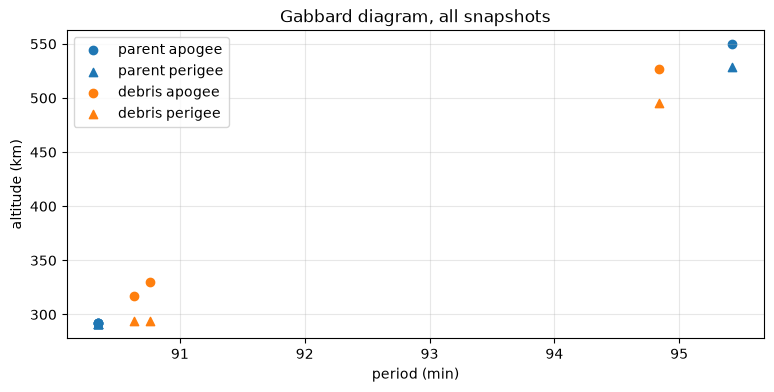

In [4]:
from kessler.orbits.elements import apogee_alt_km, perigee_alt_km, period_min
g = json.load(open(B/'site/events/starlink-34343/gabbard.json'))
g = pd.DataFrame(g)
fig, ax = plt.subplots()
for par, c in [(True,'tab:blue'),(False,'tab:orange')]:
    s = g[g.parent==par]; ax.scatter(s.period, s.apo, c=c, marker='o', label=('parent' if par else 'debris')+' apogee'); ax.scatter(s.period, s.peri, c=c, marker='^', label=('parent' if par else 'debris')+' perigee')
ax.set_xlabel('period (min)'); ax.set_ylabel('altitude (km)'); ax.legend(); ax.set_title('Gabbard diagram, all snapshots');

In [5]:
s = json.load(open(B/'site/events/starlink-34343/summary.json'))['solution']; {k: s[k] for k in ['t_p05','t_p50','t_p95','spread_km','flags']}

{'t_p05': '2026-03-31T00:10:00+00:00',
 't_p50': '2026-03-31T22:55:25.561404220+00:00',
 't_p95': '2026-03-31T22:55:25.561404220+00:00',
 'spread_km': 9995536531783.668,
 'flags': ['FEW_FRAGMENTS',
  'MULTIMODAL',
  'LOW_CONFIDENCE',
  'LONG_BACKPROP',
  'STALE_PARENT']}